# Word ↔ brain decoding with HTFA (Mitchell et al., 2008)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ContextLab/htfa/blob/main/docs/tutorials/09_word_decoding_mitchell2008.ipynb)

Mitchell et al. (2008, *Science* 320:1191) recorded fMRI while nine participants viewed 60 concrete nouns (12 categories of 5 words, e.g. *dog*, *hammer*, *house*), each with a line drawing, six times each. They showed that a linear map from word features to voxel activity predicts the images of nouns that were left out of the training set. This notebook repeats the two directions of that analysis with HTFA factor weights in place of voxels and modern sentence embeddings in place of the original verb co-occurrence features:

1. **brain prediction**: word embedding → HTFA weights → predicted image of the held-out word in the held-out participant's voxels;
2. **word decoding**: the held-out participant's real HTFA weights → predicted embedding → which of the 60 nouns?

Both mappings are learned on the other 8 participants and never see the held-out word in any participant. The held-out participant's weights and images are z-scored and centered with the mean and SD of its own 59 training words, so that fold-specific normalization excludes the held-out word. Initial voxel standardization and the unsupervised HTFA fit use the complete runs: this is transductive template evaluation, not a fully held-out preprocessing pipeline.

**Run time.** By default the notebook loads checksum-verified saved fits, embeddings and permutation nulls, then recomputes the decoding and figures. The cells print the provenance and timing of the assets actually used. `REFIT`, `RECOMPUTE_EMBEDDINGS` and `RECOMPUTE_NULL` enable recomputation; refitting and permutation testing can take substantially longer. Downloads are cached.

**Data.** The nine `data-science-P*.mat` files (about 60 MB each) come from the [dataset page](https://www.cs.cmu.edu/afs/cs/project/theo-73/www/science2008/data.html) and are cached in `~/.cache/htfa/mitchell2008` (or `$HTFA_DATA/mitchell2008`). The next cell installs `htfa` from GitHub if it is not installed; matplotlib, nilearn, `hypertools` and `sentence-transformers` (the `tutorials` extra) are installed the first time they are used.

In [2]:
# Install htfa if it is missing (for example on Colab); other packages
# install themselves the first time they are needed.
try:
    import htfa  # noqa: F401
except ImportError:
    %pip install -q "htfa @ git+https://github.com/ContextLab/htfa"

## 1. Download

Each file holds one participant: 360 trial images (60 nouns × 6 presentations). Per the dataset documentation, each trial image is the mean percent signal change 4 to 8 s after stimulus onset; the data were corrected for slice timing, motion and linear trend, high-pass filtered, normalized to MNI space with SPM and resampled to 3 × 3 × 6 mm voxels.

In [3]:
import hashlib
import json
import os
import time
import urllib.request
import warnings
from pathlib import Path

import nibabel as nib
import numpy as np
import scipy.io
from joblib import Parallel, delayed
from sklearn.exceptions import ConvergenceWarning

import htfa
from htfa.tfa import standardize_data


def load_average():
    return os.getloadavg() if hasattr(os, "getloadavg") else np.full(3, np.nan)


t_notebook = time.perf_counter()
plt = htfa.require("matplotlib.pyplot")
datasets = htfa.require("nilearn.datasets")
plotting = htfa.require("nilearn.plotting")
print("htfa", htfa.__version__)
print(
    "CPUs:",
    os.cpu_count(),
    "| load average (1, 5, 15 min):",
    load_average(),
)

URL = "https://www.cs.cmu.edu/afs/cs/project/theo-73/www/science2008"
DATA_HOME = Path(os.environ.get("HTFA_DATA", Path.home() / ".cache" / "htfa"))
CACHE = DATA_HOME / "mitchell2008"
CACHE.mkdir(parents=True, exist_ok=True)


def fetch(name):
    """Download one file of the dataset into CACHE (once) and return its path."""
    path = CACHE / name
    if not path.exists():
        tmp = path.with_suffix(".part")
        urllib.request.urlretrieve(f"{URL}/{name}", tmp)
        tmp.rename(path)
    return path


t0 = time.perf_counter()
files = [fetch(f"data-science-P{p}.mat") for p in range(1, 10)]
print(
    f"{len(files)} files, {sum(f.stat().st_size for f in files) / 1e6:.0f} MB, "
    f"{time.perf_counter() - t0:.0f} s (0 s when already cached)"
)

htfa 0.1.0
CPUs: 12 | load average (1, 5, 15 min): (5.2314453125, 6.85791015625, 7.82568359375)
9 files, 538 MB, 0 s (0 s when already cached)


## 2. Load the trials and the voxel coordinates

`meta.colToCoord` gives the (1-based) voxel indices of every column of `data`. The dataset's `functions.tar.gz` converts them to MNI millimetres with a fixed matrix (`get_mni_coordinates.m`), copied below; its in-plane step is 3.125 mm. Each participant has a different set of voxels, which HTFA allows: the factors are functions of MNI coordinates, not of voxel indices.

In [4]:
# get_mni_coordinates.m from the dataset's functions.tar.gz: 1-based voxel
# indices (i, j, k) -> MNI millimetres
VOX_TO_MNI = np.array(
    [
        [-3.125, 0.0, 0.0, 81.25],
        [0.0, 3.125, 0.0, -115.625],
        [0.0, 0.0, 6.0, -54.0],
        [0.0, 0.0, 0.0, 1.0],
    ]
)
AFFINE = VOX_TO_MNI.copy()  # the same map for 0-based indices, for NIfTI images
AFFINE[:3, 3] += VOX_TO_MNI[:3, :3].sum(axis=1)


def load_participant(path):
    m = scipy.io.loadmat(path)
    meta, info = m["meta"][0, 0], m["info"][0]
    X = np.vstack([trial[0].ravel() for trial in m["data"][:, 0]]).T  # (V, 360)
    ijk = meta["colToCoord"].astype(int) - 1  # 0-based voxel indices
    coords = nib.affines.apply_affine(AFFINE, ijk)
    words = np.array([str(t["word"][0]) for t in info])
    cats = np.array([str(t["cond"][0]) for t in info])
    shape = tuple(int(meta[d][0, 0]) for d in ("dimx", "dimy", "dimz"))
    return dict(X=X, coords=coords, ijk=ijk, words=words, cats=cats, shape=shape)


subjects = [load_participant(f) for f in files]
# vocabulary: the 60 nouns, sorted by category and then alphabetically
vocab_pairs = sorted(set(zip(subjects[0]["cats"], subjects[0]["words"], strict=True)))
vocab = np.array([w for _, w in vocab_pairs])
vocab_cats = np.array([c for c, _ in vocab_pairs])
for p, s in enumerate(subjects, 1):
    counts = {w: int((s["words"] == w).sum()) for w in vocab}
    assert set(s["words"]) == set(vocab) and set(counts.values()) == {6}, p
    assert set(zip(s["cats"], s["words"], strict=True)) == set(vocab_pairs), p
print("voxels per participant:", [s["X"].shape[0] for s in subjects])
print("trials per participant:", {s["X"].shape[1] for s in subjects})
print("grid:", subjects[0]["shape"], "| categories:", len(set(vocab_cats)))
print("first 12 trials of P1:", list(subjects[0]["words"][:12]))

voxels per participant: [21764, 21253, 20651, 20395, 20601, 19919, 19750, 20082, 21344]
trials per participant: {360}
grid: (51, 61, 23) | categories: 12
first 12 trials of P1: [np.str_('refrigerator'), np.str_('barn'), np.str_('bell'), np.str_('key'), np.str_('window'), np.str_('screwdriver'), np.str_('church'), np.str_('desk'), np.str_('cow'), np.str_('knife'), np.str_('train'), np.str_('beetle')]


### Check: do the coordinates land in the brain?

If the matrix is right, the voxels should fill the MNI brain. Between 99.1% and 99.3% of each participant's voxels fall inside nilearn's MNI152 brain mask, and the coordinates span about -69 to 72 mm (x), -106 to 72 mm (y) and -48 to 78 mm (z). The glass brain shows P1's voxels.

P1: 99.1% of voxels inside the MNI152 brain mask; x -69..69, y -106..72, z -48..78 mm
P2: 99.1% of voxels inside the MNI152 brain mask; x -69..69, y -103..72, z -42..72 mm
P3: 99.3% of voxels inside the MNI152 brain mask; x -69..69, y -103..72, z -48..78 mm
P4: 99.1% of voxels inside the MNI152 brain mask; x -69..69, y -103..72, z -42..72 mm
P5: 99.3% of voxels inside the MNI152 brain mask; x -69..69, y -106..69, z -48..78 mm
P6: 99.3% of voxels inside the MNI152 brain mask; x -69..69, y -106..72, z -36..72 mm
P7: 99.1% of voxels inside the MNI152 brain mask; x -69..72, y -106..72, z -36..72 mm
P8: 99.3% of voxels inside the MNI152 brain mask; x -69..69, y -106..72, z -48..78 mm
P9: 99.3% of voxels inside the MNI152 brain mask; x -69..69, y -103..72, z -48..72 mm


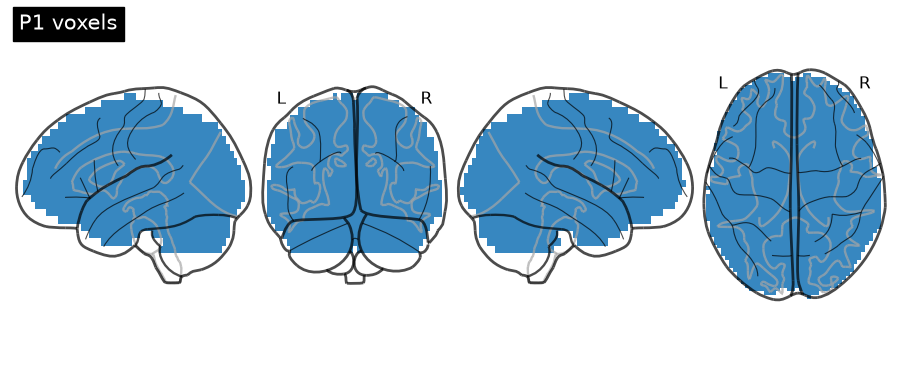

In [5]:
def to_nifti(values, s):
    """Put a vector of voxel values of participant s into a 3D NIfTI image."""
    vol = np.zeros(subjects[s]["shape"])
    i, j, k = subjects[s]["ijk"].T
    vol[i, j, k] = values
    return nib.Nifti1Image(vol, AFFINE)


mni_mask = datasets.load_mni152_brain_mask()
inv = np.linalg.inv(mni_mask.affine)
mask_data = mni_mask.get_fdata() > 0
for p, s in enumerate(subjects, 1):
    idx = np.rint(nib.affines.apply_affine(inv, s["coords"])).astype(int)
    inside = mask_data[tuple(idx.T)].mean()
    lo, hi = s["coords"].min(0), s["coords"].max(0)
    print(
        f"P{p}: {inside:.1%} of voxels inside the MNI152 brain mask; "
        f"x {lo[0]:.0f}..{hi[0]:.0f}, y {lo[1]:.0f}..{hi[1]:.0f}, "
        f"z {lo[2]:.0f}..{hi[2]:.0f} mm"
    )
plotting.plot_glass_brain(
    to_nifti(np.ones(len(subjects[0]["coords"])), 0),
    display_mode="lyrz",
    cmap="Blues",
    vmin=0,
    vmax=1.5,
    colorbar=False,
    title="P1 voxels",
)
plt.show()

## 3. Fit HTFA (K = 100)

The fit is unsupervised: it sees the 360 trial images of each participant, not the word labels. Each iteration solves for the centers and widths on a random subset of at most 10,000 voxels (`max_voxels=10000`; all 360 trials); the weights always use all voxels (see the *Performance* page). `init='ncorr'` uses one start per participant instead of the three of `init='auto'`. By default (`REFIT = False`) the cell downloads a saved copy of this fit with `htfa.datasets.fetch_tutorial_fit` from the `tutorial-data-v1` data release of the htfa repository, checks its SHA-256 and loads it with `np.load(..., allow_pickle=False)`; the printed lines give its settings and the htfa commit it was made with. `REFIT = True` fits it again (the result is not cached).

The cell reports the saved fit duration, iteration count and convergence status. Reaching the iteration limit does not establish convergence.

**Design choice.** This template is fitted with all nine participants, including the one held out below; the held-out participant's word labels are never used, but its unlabelled images shaped the template.

saved fit: htfa.datasets.fetch_tutorial_fit('mitchell2008_K100'), SHA-256 checked
settings: {"K": 100, "max_voxels": 10000, "init": "ncorr", "backend": "numpy", "n_jobs": 3, "random_state": 0}
fitted with htfa 0.1.0 at commit 08b333294a24b2a93db35b883d82ae08b7a04adb, in 531 s
global iterations: 10 | converged: False
weights per participant: {(100, 360)}


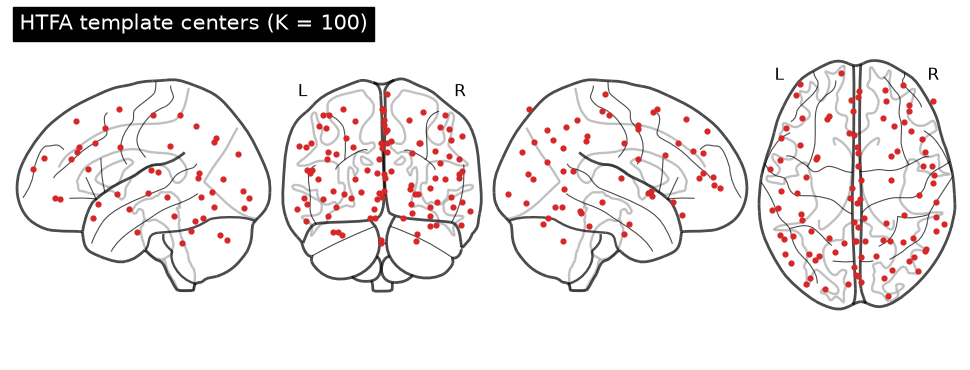

In [6]:
# Fit from scratch (True; the saved fit took 1008 s on 12 CPUs), or download
# the saved fit made with the same settings (False, the default; 2.5 MB).
REFIT = False
NAME = "mitchell2008_K100"
Xs = [s["X"] for s in subjects]
Rs = [s["coords"] for s in subjects]
fit_kwargs = dict(
    K=100, max_voxels=10000, init="ncorr", backend="numpy", n_jobs=3, random_state=0
)


if REFIT:
    t0 = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model = htfa.fit(Xs, coords=Rs, **fit_kwargs).model
    print(f"fit time: {time.perf_counter() - t0:.0f} s")
    print("warnings:", sorted({w.category.__name__ for w in caught}))
else:
    fit = htfa.datasets.fetch_tutorial_fit(NAME)
    assert json.loads(str(fit["settings"])) == fit_kwargs, fit["settings"]
    assert list(fit["n_voxels"]) == [X.shape[0] for X in Xs]
    model = htfa.HTFA(**fit_kwargs)  # filled with the saved estimates
    model.centers_ = list(fit["centers"])
    model.widths_ = list(fit["widths"])
    model.weights_ = list(fit["weights"])
    model.global_centers_ = fit["global_centers"]
    model.global_widths_ = fit["global_widths"]
    model.n_iter_ = int(fit["n_iter"])
    model.converged_ = bool(fit["converged"])
    print(f"saved fit: htfa.datasets.fetch_tutorial_fit({NAME!r}), SHA-256 checked")
    print("settings:", fit["settings"])
    print(
        f"fitted with htfa {fit['htfa_version']} at commit {fit['htfa_commit']}, "
        f"in {float(fit['fit_seconds']):.0f} s"
    )
res = htfa.HTFAResults(model, htfa.load(Xs, coords=Rs))
print("global iterations:", model.n_iter_, "| converged:", model.converged_)
print("weights per participant:", {w.shape for w in res.weights})
plotting.plot_connectome(
    np.zeros((100, 100)),
    res.global_centers,
    node_size=12,
    node_color="tab:red",
    display_mode="lyrz",
    colorbar=False,
    title="HTFA template centers (K = 100)",
)
plt.show()

## 4. One weight vector per word

For each participant, the 6 presentations of each noun are averaged: the weights give a (60, K) matrix per participant, and the per-voxel z-scored data (the same z-scoring the fit applied) give a (60, V) matrix of word images. The `mean r(F w, word image)` line measures how well K = 100 factors can represent a word image when the weights are known.

The template is a compromise between participants. The next cell reports how often local factors are nearest to their matched template factor, their displacement, and template spacing. These diagnostics should be read alongside the reconstruction scores rather than assuming perfect anatomical correspondence.

In [7]:
# Per-word means: 6 presentations -> one weight vector (K) and one image (V)
Ws, imgs = [], []
for s, w in zip(subjects, res.weights, strict=True):
    Z = standardize_data(s["X"], "auto")  # the per-voxel z-scoring the fit used
    Ws.append(np.stack([w[:, s["words"] == v].mean(axis=1) for v in vocab]))
    imgs.append(np.stack([Z[:, s["words"] == v].mean(axis=1) for v in vocab]))
Fs = [res.factors(s) for s in range(len(subjects))]
print("per-word weights:", Ws[0].shape, "| per-word images of P1:", imgs[0].shape)

# How much of the per-word images the K = 100 factors can represent at all
fit_r = [
    np.mean([np.corrcoef(F @ W[i], img[i])[0, 1] for i in range(60)])
    for F, W, img in zip(Fs, Ws, imgs, strict=True)
]
print("mean r(F w, word image) per participant:", np.round(fit_r, 2))

# How far each participant's local factors moved from the template
G = model.global_centers_
own, shift = [], []
for c in model.centers_:
    d = np.linalg.norm(c[:, None] - G[None], axis=2)  # (K local, K template)
    own.append(d.argmin(1) == np.arange(len(G)))
    shift.append(np.diag(d))
dG = np.linalg.norm(G[:, None] - G[None], axis=2)
np.fill_diagonal(dG, np.inf)
print(
    f"local factors nearest to their own template factor: {np.mean(own):.1%} "
    f"of {np.size(own)}; median distance to it {np.median(shift):.1f} mm; "
    f"median template nearest-neighbour spacing {np.median(dG.min(1)):.1f} mm"
)

per-word weights: (60, 100) | per-word images of P1: (60, 21764)
mean r(F w, word image) per participant: [0.44 0.39 0.42 0.39 0.47 0.43 0.43 0.43 0.43]
local factors nearest to their own template factor: 81.1% of 900; median distance to it 8.9 mm; median template nearest-neighbour spacing 18.6 mm


## 5. Word embeddings

**Model.** `Qwen/Qwen3-Embedding-0.6B` (Apache-2.0, 596M parameters, revision `97b0c614be4d77ee51c0cef4e5f07c00f9eb65b3`). Its model card reports a mean task score of 64.33 on MTEB (Multilingual) and 70.70 on MTEB (English, v2), above the other models of 0.6B parameters or fewer that the card lists (e.g. multilingual-e5-large-instruct, 63.22 and 65.53); the card's comparison scores were taken from the MTEB leaderboard on 2025-05-24. It is not gated (it downloads without a Hugging Face token; the cell removes any token from the environment) and runs on a CPU or a free Colab runtime. EmbeddingGemma-300m, the first suggestion, is gated (its licence must be accepted on Hugging Face before download).

**hypertools.** `hypertools.tools.format_data` (hypertools 1.1) accepts a sentence-transformers model id as its `vectorizer`, so the embeddings below are computed through hypertools; `semantic=None` skips the topic-model stage and `ppca=False` leaves the 1024 dimensions as they are. Each noun is embedded on its own, without a prompt.

**What is loaded.** By default (`RECOMPUTE_EMBEDDINGS = False`) the cell loads saved embeddings with `htfa.datasets.fetch_tutorial_fit`: the output of the call below, computed once on 2026-10-25 with the model at the revision above. They are the embeddings the saved permutation null of section 7 was computed with. `RECOMPUTE_EMBEDDINGS = True` computes them again; sentence-transformers then loads the model's current revision in its default precision (bfloat16 on a CPU in a Linux test run), so the values can differ slightly from the saved ones.

Embeddings of nouns from the same category are more similar (mean *r* 0.705) than those of nouns from different categories (0.635). The figure is drawn by `hypertools.plot`: the embeddings reduced to two dimensions with PCA, one color per category (`hue`), and the nouns of the nearest-neighbour pairs below labelled with its `labels` argument (*dresser* is the unlabelled furniture point next to *dress*, which is left out because the two labels would overlap). In the PCA projection the categories form loose clusters. Each noun is embedded on its own, without context, so nearest neighbours are partly lexical rather than semantic (printed below: *hammer* is nearest to *arm*, *celery* to *bee* and *dress* to *dresser*).

saved embeddings: Qwen/Qwen3-Embedding-0.6B at revision 97b0c614be4d77ee51c0cef4e5f07c00f9eb65b3, computed on Darwin arm64 (Apple M2 Max), 2026-10-25
embeddings: (60, 1024)
mean r between embeddings: same category 0.705, different categories 0.635
nearest neighbour: hammer -> arm, celery -> bee, dress -> dresser


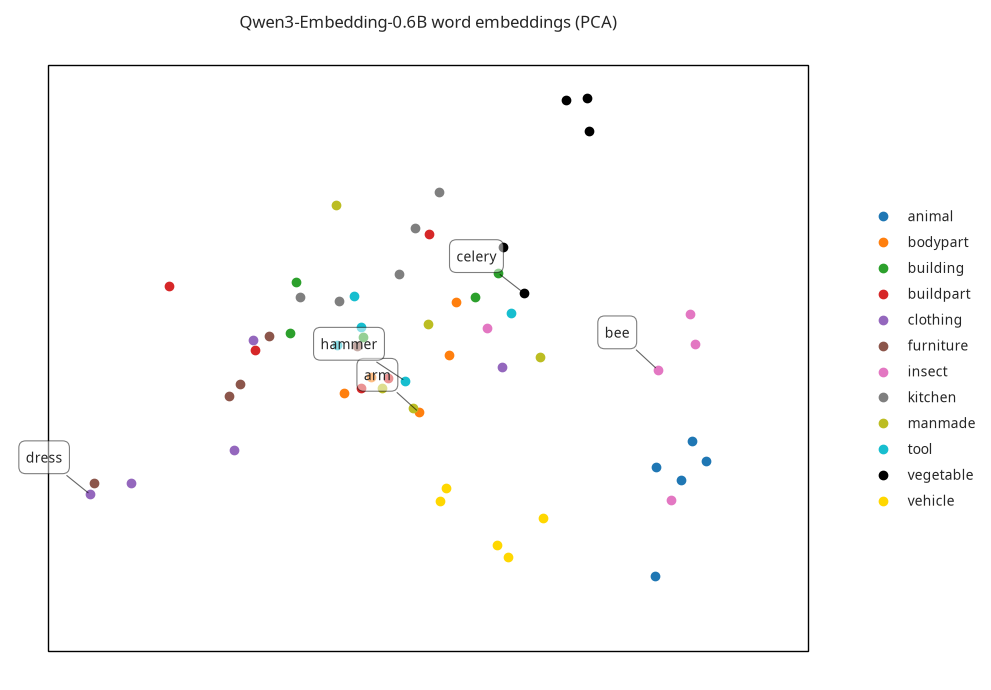

In [8]:
for key in ("HF_TOKEN", "HUGGING_FACE_HUB_TOKEN"):  # the model is not gated
    os.environ.pop(key, None)
import logging  # noqa: E402

hyp = htfa.require("hypertools", extra="tutorials")

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)  # font notices

EMBED_MODEL = "Qwen/Qwen3-Embedding-0.6B"
# Embed the 60 nouns again (True), or load the saved embeddings that the saved
# permutation null of section 7 was computed with (False, the default).
RECOMPUTE_EMBEDDINGS = False
if RECOMPUTE_EMBEDDINGS:
    t0 = time.perf_counter()
    E = np.asarray(
        hyp.tools.format_data(
            list(vocab), vectorizer=EMBED_MODEL, semantic=None, corpus=None, ppca=False
        )[0]
    )
    print(f"embedding time: {time.perf_counter() - t0:.0f} s")
else:
    saved_E = htfa.datasets.fetch_tutorial_fit("mitchell2008_embeddings")
    assert list(saved_E["vocab"]) == list(vocab)
    E = saved_E["E"]
    print(
        f"saved embeddings: {saved_E['embedding_model']} at revision "
        f"{saved_E['embedding_revision']}, computed on {saved_E['machine']}"
    )
print("embeddings:", E.shape)
C = np.corrcoef(E)
same = np.equal.outer(vocab_cats, vocab_cats) & ~np.eye(60, dtype=bool)
print(
    f"mean r between embeddings: same category {C[same].mean():.3f}, "
    f"different categories {C[~np.equal.outer(vocab_cats, vocab_cats)].mean():.3f}"
)
C_nn = np.where(np.eye(60, dtype=bool), -np.inf, C)
nearest = {w: vocab[C_nn[vocab == w].argmax()] for w in ("hammer", "celery", "dress")}
print("nearest neighbour:", ", ".join(f"{a} -> {b}" for a, b in nearest.items()))
# tab10 plus two colors: 12 distinguishable colors, one per category
palette = list(plt.get_cmap("tab10").colors) + ["black", "gold"]
labelled = ("hammer", "arm", "celery", "bee", "dress")  # pairs printed above
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)  # hypertools: ipympl not installed
    geo = hyp.plot(
        E,
        "o",
        hue=list(vocab_cats),
        labels=[w if w in labelled else None for w in vocab],
        palette=palette,
        ndims=2,
        reduce="PCA",
        legend=True,
        backend="matplotlib",
        size=[10, 7],
        title="Qwen3-Embedding-0.6B word embeddings (PCA)",
    )

## 6. Leave-one-participant-out, leave-one-word-out decoding

For each held-out participant *s* and each held-out word *i* (9 × 60 folds):

- **Normalization.** Each participant's (59, K) training weights are z-scored per factor across the 59 training words; the held-out participant's weights use the mean and SD of its own 59 training words.
- **Brain prediction.** Ridge regression from the embedding (1024) to the z-scored weights (K), trained on the 8 × 59 (participant, word) pairs. The predicted weights for word *i*, rescaled by participant *s*'s SDs, give the predicted image `F_s @ w` in participant *s*'s voxels. It is compared with the real image of every word after subtracting participant *s*'s mean image over the 59 training words (Mitchell et al. also removed the mean image). Reconstruction accuracy is the Pearson *r* with the real image of word *i*.
- **Word decoding.** Ridge regression from the z-scored weights to the embedding, trained on the same pairs, applied to participant *s*'s real weights for word *i*. The predicted embedding is correlated with the 60 noun embeddings, all centered on the 59 training words' mean and projected onto the span of the 59 centered training embeddings. A ridge prediction always lies in that span (at most 58 of the 1024 dimensions); the training nouns lie entirely in it, but the held-out noun does not, so without the projection part of the held-out noun's embedding can never be matched and it is ranked below the training nouns systematically, also when the labels are permuted. The projection puts all 60 candidates in the same subspace; it uses only the embeddings, not the brain data.
- **Ridge penalty.** Chosen in every fold from 17 values (1e-3 to 1e5) by 5-fold cross-validation over the 59 training words (all 8 participants' rows of a word in the same inner fold).

**Scores** (from the 60 × 60 matrix `S[i, j]` = correlation of the prediction for word *i* with candidate *j*):

- *top-1*: the true candidate has the highest correlation (chance 1/60 ≈ 0.017);
- *rank accuracy*: fraction of the 59 wrong candidates that score below the true one (chance 0.5);
- *2-vs-2*: Mitchell's test over all 1770 word pairs, correct when `S[i, i] + S[j, j] > S[i, j] + S[j, i]` (chance 0.5). Mitchell et al. retrained without both words of each pair; here the two predictions come from the two leave-one-word-out folds.

In [9]:
ALPHAS = np.logspace(-3, 5, 17)


def ridge_solution(A, B):
    """Center A and B and take the SVD of A: ridge for every alpha at once."""
    a_mu, b_mu = A.mean(0), B.mean(0)
    U, sv, Vt = np.linalg.svd(A - a_mu, full_matrices=False)
    return a_mu, b_mu, Vt, sv, U.T @ (B - b_mu)


def ridge_predict(sol, A_new, alpha):
    a_mu, b_mu, Vt, sv, UtB = sol
    return (A_new - a_mu) @ (Vt.T @ ((sv / (sv**2 + alpha))[:, None] * UtB)) + b_mu


def ridge_cv_predict(A, B, groups, A_new, alphas, n_folds=5):
    """Ridge A -> B, alpha chosen by 5-fold CV over groups (words); predict A_new."""
    rng = np.random.default_rng(0)
    folds = np.array_split(rng.permutation(np.unique(groups)), n_folds)
    err = np.zeros(len(alphas))
    for f in folds:
        test = np.isin(groups, f)
        sol = ridge_solution(A[~test], B[~test])
        err += [((ridge_predict(sol, A[test], a) - B[test]) ** 2).sum() for a in alphas]
    best = alphas[np.argmin(err)]
    return ridge_predict(ridge_solution(A, B), A_new, best), best


def corr_rows(P, Q):
    """Pearson r of each row of P with each row of Q."""
    P = P - P.mean(1, keepdims=True)
    Q = Q - Q.mean(1, keepdims=True)
    P = P / np.linalg.norm(P, axis=1, keepdims=True)
    Q = Q / np.linalg.norm(Q, axis=1, keepdims=True)
    return P @ Q.T


def decode_participant(s, E, Ws, Fs, imgs):
    """Leave participant s and, in turn, each word out of the mappings.

    Returns S_brain[i, j] = r(image predicted for word i, real image of word j),
    S_word[i, j] = r(embedding predicted from word i's weights, embedding of j),
    ceiling[i] = r(F_s w_s[i], real image of word i), all in participant s.
    """
    train = [t for t in range(len(Ws)) if t != s]
    n = len(E)
    S_brain, S_word, ceiling = np.zeros((n, n)), np.zeros((n, n)), np.zeros(n)
    for i in range(n):
        keep = np.arange(n) != i
        # z-score each participant's factor weights over its 59 training words
        Z = np.stack(
            [(Ws[t][keep] - Ws[t][keep].mean(0)) / Ws[t][keep].std(0) for t in train]
        )  # (8, 59, K)
        mu, sd = Ws[s][keep].mean(0), Ws[s][keep].std(0)
        z_s = (Ws[s][i] - mu) / sd
        dev = imgs[s] - imgs[s][keep].mean(0)  # images minus the 59-word mean
        # a. embedding -> weights -> image. The 8 participants share the inputs,
        # so ridge on the 8 x 59 rows equals ridge on the participant-mean
        # targets with alpha / 8.
        w_hat, _ = ridge_cv_predict(
            E[keep], Z.mean(0), np.arange(n - 1), E[i : i + 1], ALPHAS / len(train)
        )
        S_brain[i] = corr_rows((Fs[s] @ (w_hat[0] * sd))[None], dev)[0]
        ceiling[i] = corr_rows((Fs[s] @ (Ws[s][i] - mu))[None], dev[i : i + 1])[0, 0]
        # b. weights -> embedding -> word
        e_hat, _ = ridge_cv_predict(
            Z.reshape(-1, Z.shape[-1]),
            np.tile(E[keep], (len(train), 1)),
            np.tile(np.arange(n - 1), len(train)),
            z_s[None],
            ALPHAS,
        )
        # compare in the span of the 59 centered training embeddings, the only
        # directions a ridge prediction can take (see the text above)
        e_mu = E[keep].mean(0)
        Q = np.linalg.svd((E[keep] - e_mu).T, full_matrices=False)[0]
        S_word[i] = corr_rows(e_hat - e_mu, (E - e_mu) @ Q @ Q.T)[0]
    return S_brain, S_word, ceiling


def scores(S):
    """Top-1 accuracy, normalized rank accuracy and 2-vs-2 accuracy."""
    n, d = len(S), np.diag(S)
    rank = np.mean([(np.delete(S[i], i) < d[i]).mean() for i in range(n)])
    a, b = np.triu_indices(n, 1)
    two = np.mean(d[a] + d[b] > S[a, b] + S[b, a])
    return np.mean(S.argmax(1) == np.arange(n)), rank, two

### Results

The table lists, per held-out participant, the mean reconstruction *r* over the 60 words, the mean ceiling *r* (a reference value: the real weights' factor image against the same real image), and the accuracies of section 6.

In [10]:
t0 = time.perf_counter()
out = Parallel(n_jobs=3)(
    delayed(decode_participant)(s, E, Ws, Fs, imgs) for s in range(len(subjects))
)
S_brain, S_word, ceiling = (np.stack(x) for x in zip(*out, strict=True))
print(f"decoding time: {time.perf_counter() - t0:.0f} s")
recon_r = np.array([np.diag(S) for S in S_brain])  # (9, 60)
brain = np.array([scores(S) for S in S_brain])  # columns: top-1, rank, 2-vs-2
word = np.array([scores(S) for S in S_word])
print(
    "participant | recon r | ceiling r | brain rank | brain 2v2 | "
    "word top-1 | word rank | word 2v2"
)
for p in range(len(subjects)):
    print(
        f"P{p + 1:<10} | {recon_r[p].mean():7.3f} | {ceiling[p].mean():9.3f} | "
        f"{brain[p, 1]:10.3f} | {brain[p, 2]:9.3f} | {word[p, 0]:10.3f} | "
        f"{word[p, 1]:9.3f} | {word[p, 2]:8.3f}"
    )
print(
    f"{'mean':<11} | {recon_r.mean():7.3f} | {ceiling.mean():9.3f} | "
    f"{brain[:, 1].mean():10.3f} | {brain[:, 2].mean():9.3f} | "
    f"{word[:, 0].mean():10.3f} | {word[:, 1].mean():9.3f} | "
    f"{word[:, 2].mean():8.3f}"
)
print(
    "chance      |         |           |      0.500 |     0.500 |      "
    f"{1 / 60:.3f} |     0.500 |    0.500"
)

decoding time: 18 s
participant | recon r | ceiling r | brain rank | brain 2v2 | word top-1 | word rank | word 2v2
P1          |   0.051 |     0.438 |      0.676 |     0.728 |      0.017 |     0.701 |    0.755
P2          |   0.014 |     0.395 |      0.547 |     0.572 |      0.000 |     0.543 |    0.579
P3          |   0.018 |     0.418 |      0.567 |     0.598 |      0.000 |     0.506 |    0.510
P4          |   0.021 |     0.391 |      0.597 |     0.649 |      0.000 |     0.585 |    0.609
P5          |   0.001 |     0.475 |      0.500 |     0.488 |      0.017 |     0.453 |    0.437
P6          |   0.019 |     0.432 |      0.582 |     0.623 |      0.017 |     0.505 |    0.529
P7          |   0.017 |     0.426 |      0.569 |     0.606 |      0.017 |     0.555 |    0.582
P8          |   0.020 |     0.430 |      0.580 |     0.618 |      0.083 |     0.571 |    0.585
P9          |   0.014 |     0.427 |      0.558 |     0.571 |      0.017 |     0.618 |    0.669
mean        |   0.019 |     0.

The table distinguishes image-reconstruction correlation, factor-space ceiling, candidate ranking, pairwise discrimination and top-1 identification. They answer different questions: good rank accuracy need not imply accurate voxel values or reliable top-1 identification. Compare participants as well as the mean; the permutation test below evaluates the mean statistics against relabelled embeddings.

## 7. Permutation test

Each permutation assigns the 60 embeddings to the 60 nouns at random and reruns the whole procedure (both mappings, all 540 folds, the inner choice of the penalty). The statistic is the mean over the 9 participants; *p* = (1 + number of permutations at least as large) / (1 + `N_PERMUTATIONS`). With the default `N_PERMUTATIONS = 20` the smallest possible *p* is 1/21 ≈ 0.048; setting it to 100 reproduces the full analysis (smallest possible *p* 1/101 ≈ 0.010).

**What is loaded.** By default (`RECOMPUTE_NULL = False`) the cell loads a saved null for 20 or 100 permutations with `htfa.datasets.fetch_tutorial_fit`. It was computed by this notebook with the saved fit (section 3) and the saved embeddings (section 5), the inputs of the observed statistics above; the printed line says where and in how long. `RECOMPUTE_NULL = True` reruns the permutations. It is required when `REFIT` or `RECOMPUTE_EMBEDDINGS` is True, so that the observed statistics and the null come from the same fit and embeddings.

In [11]:
# Number of permutations: 20 by default (smallest possible p = 1/21);
# 100 reproduces the full analysis (smallest possible p = 1/101).
N_PERMUTATIONS = 20
# Recompute the null (True), or load the saved null for 20 or 100 permutations,
# computed with the saved fit and the saved embeddings (False, the default).
RECOMPUTE_NULL = False
names = [
    "recon r",
    "brain top-1",
    "brain rank",
    "brain 2v2",
    "word top-1",
    "word rank",
    "word 2v2",
]
seeds = 1000 + np.arange(N_PERMUTATIONS)


def permuted_means(seed):
    """Relabel the 60 embeddings at random and rerun the whole decoding."""
    E_perm = E[np.random.default_rng(seed).permutation(60)]
    res_p = [decode_participant(s, E_perm, Ws, Fs, imgs) for s in range(len(subjects))]
    b = np.array([scores(r[0]) for r in res_p]).mean(0)
    w = np.array([scores(r[1]) for r in res_p]).mean(0)
    recon = np.mean([np.diag(r[0]).mean() for r in res_p])
    return np.r_[recon, b, w]


if RECOMPUTE_NULL:
    t0 = time.perf_counter()
    null = np.array(Parallel(n_jobs=4)(delayed(permuted_means)(s) for s in seeds))
    print(f"permutation time: {time.perf_counter() - t0:.0f} s")
else:
    if REFIT or RECOMPUTE_EMBEDDINGS:
        raise RuntimeError(
            "the saved null was computed with the saved fit and the saved "
            "embeddings; set RECOMPUTE_NULL = True to compute it from the ones "
            "used here"
        )
    if N_PERMUTATIONS not in (20, 100):
        raise ValueError(
            "saved nulls exist for 20 and 100 permutations; set RECOMPUTE_NULL = True"
        )
    saved_null = htfa.datasets.fetch_tutorial_fit(f"mitchell2008_null_{N_PERMUTATIONS}")
    if str(saved_null["fit_sha256"]) != htfa.datasets.TUTORIAL_FITS[NAME][1]:
        raise RuntimeError("Saved permutation null does not match the registered fit")
    if (
        str(saved_null["embeddings_sha256_of_E"])
        != hashlib.sha256(E.tobytes()).hexdigest()
    ):
        raise RuntimeError("Saved permutation null does not match these embeddings")
    assert list(saved_null["statistics"]) == names
    assert np.array_equal(saved_null["seeds"], seeds)
    null = saved_null["null"]
    print(
        f"saved null: {N_PERMUTATIONS} permutations; full generation run "
        f"({int(saved_null.get('generation_permutations', N_PERMUTATIONS))} "
        f"permutations): "
        f"{float(saved_null['seconds']):.0f} s on {saved_null['machine']} "
        f"at htfa commit {saved_null['htfa_commit']}"
    )
observed = np.r_[recon_r.mean(), brain.mean(0), word.mean(0)]
print(f"{'statistic (mean of 9)':<22} observed  null mean  null 95th pct  p")
for k, name in enumerate(names):
    p = (1 + np.sum(null[:, k] >= observed[k])) / (1 + len(null))
    print(
        f"{name:<22} {observed[k]:8.3f}  {null[:, k].mean():9.3f}  "
        f"{np.percentile(null[:, k], 95):13.3f}  {p:.3f}"
    )

saved null: 20 permutations; full generation run (100 permutations): 1424 s on Darwin arm64 12 CPUs at htfa commit 085881c46780d0e3a2e624c7bf0d5994b8638f7e
statistic (mean of 9)  observed  null mean  null 95th pct  p
recon r                   0.019     -0.001          0.007  0.048
brain top-1               0.031      0.014          0.021  0.048
brain rank                0.575      0.498          0.528  0.048
brain 2v2                 0.606      0.493          0.531  0.048
word top-1                0.019      0.013          0.021  0.238
word rank                 0.560      0.497          0.517  0.048
word 2v2                  0.584      0.494          0.521  0.048


Use the observed statistics, null percentiles and p-values above to evaluate each metric separately. With 20 permutations, p-values cannot be smaller than 1/21. The 100-permutation asset provides finer resolution; neither setting makes these seven exploratory metrics a multiplicity-corrected family of tests.

## 8. Figures

Per participant: mean reconstruction *r* (bars), the ceiling of section 4 (black ticks) and the 95th percentile of the permutation null of the 9-participant mean (dashed); rank and 2-vs-2 accuracy in both directions (top-1 accuracy is in the table above).

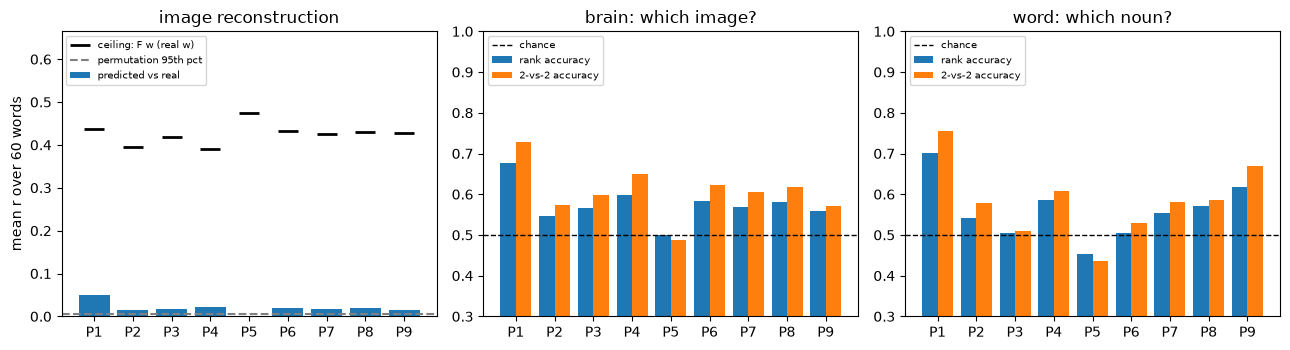

In [12]:
labels = [f"P{p}" for p in range(1, 10)]
x = np.arange(9)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].bar(x, recon_r.mean(1), color="tab:blue", label="predicted vs real")
ax[0].plot(x, ceiling.mean(1), "k_", ms=14, mew=2, label="ceiling: F w (real w)")
ax[0].axhline(
    np.percentile(null[:, 0], 95), color="gray", ls="--", label="permutation 95th pct"
)
ax[0].set(ylabel="mean r over 60 words", title="image reconstruction")
panels = ((ax[1], brain, "brain: which image?"), (ax[2], word, "word: which noun?"))
for a, M, title in panels:
    a.bar(x - 0.2, M[:, 1], 0.4, label="rank accuracy")
    a.bar(x + 0.2, M[:, 2], 0.4, label="2-vs-2 accuracy")
    a.axhline(0.5, color="k", ls="--", lw=1, label="chance")
    a.set(ylim=(0.3, 1), title=title)
for a in ax:
    a.set_xticks(x, labels)
    a.legend(fontsize=7, loc="upper left")
ax[0].set_ylim(0, max(ceiling.mean(1).max(), recon_r.mean(1).max()) * 1.4)
plt.tight_layout()
plt.show()

Ranks of the true item among the 60 candidates over all 540 held-out words; under chance they are uniform. The plot and printed summaries show whether the true item tends to rank near the top and how often it appears among the best five candidates.

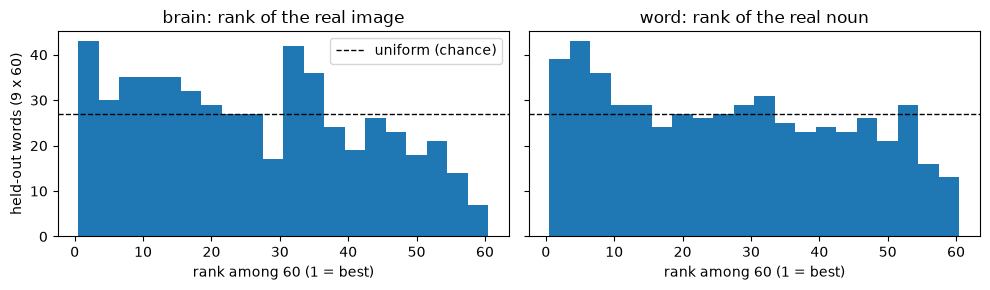

median rank: brain 25, word 26 (chance 30.5)
rank 1: brain 0.031, word 0.019; rank <= 5: brain 0.120, word 0.119


In [13]:
def true_ranks(S):
    """Rank of the true item among the 60 candidates (1 = best), per held-out word."""
    return np.array([1 + np.sum(np.delete(row, i) > row[i]) for i, row in enumerate(S)])


ranks_b = np.concatenate([true_ranks(S) for S in S_brain])
ranks_w = np.concatenate([true_ranks(S) for S in S_word])
fig, ax = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
bins = np.arange(0.5, 61.5, 3)
for a, r, title in (
    (ax[0], ranks_b, "brain: rank of the real image"),
    (ax[1], ranks_w, "word: rank of the real noun"),
):
    a.hist(r, bins=bins, color="tab:blue")
    a.axhline(len(r) / 20, color="k", ls="--", lw=1, label="uniform (chance)")
    a.set(xlabel="rank among 60 (1 = best)", title=title)
ax[0].set_ylabel("held-out words (9 x 60)")
ax[0].legend()
plt.tight_layout()
plt.show()
print(
    f"median rank: brain {np.median(ranks_b):.0f}, word {np.median(ranks_w):.0f} "
    "(chance 30.5)"
)
print(
    f"rank 1: brain {np.mean(ranks_b == 1):.3f}, word {np.mean(ranks_w == 1):.3f}; "
    f"rank <= 5: brain {np.mean(ranks_b <= 5):.3f}, word {np.mean(ranks_w <= 5):.3f}"
)

Images of four nouns for P1 (the nouns were fixed before the results were computed). Each image is the deviation from P1's mean image over the 59 training words, z-scored across voxels and drawn on the same color scale (±3; |z| < 1 not drawn).

Left: the real image (mean of 6 presentations). Middle (`F w`): the same image represented by the 100 factors with P1's real weights. Right: the image predicted from the noun's embedding by the mapping learned on the other 8 participants. The predictions are smooth because they are sums of 100 broad factors; the real single-word images are dominated by noise.

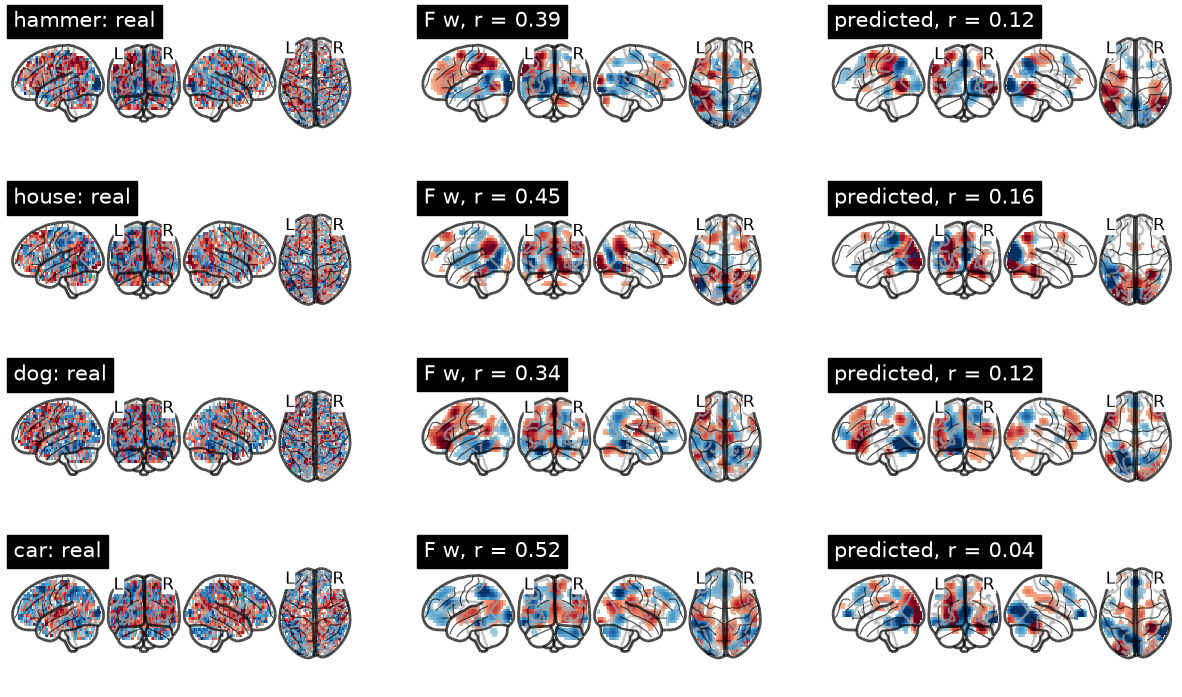

z-scored images, |z| < 1 not drawn, color scale -3 (blue) to +3 (red)


In [14]:
s = 0  # P1
examples = ["hammer", "house", "dog", "car"]  # chosen before the results were seen
z = lambda v: (v - v.mean()) / v.std()  # noqa: E731
fig, axes = plt.subplots(len(examples), 3, figsize=(15, 2.2 * len(examples)))
for row, w in zip(axes, examples, strict=True):
    i = int(np.flatnonzero(vocab == w)[0])
    keep = np.arange(60) != i
    real = imgs[s][i] - imgs[s][keep].mean(0)
    # rerun the word-i fold of participant s to get its predicted image
    train = [t for t in range(9) if t != s]
    Z = np.stack(
        [(Ws[t][keep] - Ws[t][keep].mean(0)) / Ws[t][keep].std(0) for t in train]
    )
    w_hat, _ = ridge_cv_predict(
        E[keep], Z.mean(0), np.arange(59), E[i : i + 1], ALPHAS / 8
    )
    pred = Fs[s] @ (w_hat[0] * Ws[s][keep].std(0))
    r = np.corrcoef(pred, real)[0, 1]
    assert np.isclose(r, S_brain[s, i, i])
    in_factors = Fs[s] @ (Ws[s][i] - Ws[s][keep].mean(0))  # real weights, F w
    r_f = np.corrcoef(in_factors, real)[0, 1]
    panels = (
        (row[0], real, f"{w}: real"),
        (row[1], in_factors, f"F w, r = {r_f:.2f}"),
        (row[2], pred, f"predicted, r = {r:.2f}"),
    )
    for a, v, t in panels:
        plotting.plot_glass_brain(
            to_nifti(z(v), s),
            axes=a,
            display_mode="lyrz",
            plot_abs=False,
            cmap="RdBu_r",
            vmax=3,
            threshold=1.0,
            colorbar=False,
            title=t,
        )
plt.show()
print("z-scored images, |z| < 1 not drawn, color scale -3 (blue) to +3 (red)")

## Summary

HTFA represents each participant's voxel images using K=100 shared-factor coordinates. The two decoding directions test prediction of brain images from embeddings and identification of nouns from brain activity. Inspect the observed/null table and participant-level results before drawing conclusions about either direction.

The template and voxel standardization use all participants' unlabelled images. The supervised mappings exclude the target participant and target noun, but this is not a fully inductive test of a template learned without the held-out data. The permutation test conditions on the fitted representation and saved embeddings. All cached nulls are checked against their exact fit and embedding hashes.

In [15]:
print(
    f"notebook run time: {time.perf_counter() - t_notebook:.0f} s "
    f"(load average now: {np.round(load_average(), 1)})"
)

notebook run time: 28 s (load average now: [5.3 6.7 7.7])
